# Étapes 5 & 6 — Inférence Statistique, Taxonomie K-Means & Audit du Drift MLOps

> **Référentiel méthodologique :** [Introduction à la Data Science — Étape 5 (*Le Profilage / Modélisation*) & Étape 6 (*L'Audit & La Surveillance MLOps*)](https://modules.apti.space/datascience/intro-datascience)  
> **Inspirations directes :** généralisation multidimensionnelle et auditée des clusterings K-Means et ajustements Masse–Rayon de `notebooks/example/Exo-planet/exoplanets.ipynb`.

---

## Objectifs scientifiques

1. **Étape 4→5 — Tests d'hypothèses non-paramétriques (`scipy.stats`)** :
   - **Kruskal-Wallis** ($k = 4$ méthodes) : prouver que les distributions de périodes orbitales diffèrent significativement entre *Transit*, *Radial Velocity*, *Microlensing* et *Imaging*.
   - **Mann-Whitney U** : tester l'hypothèse astrophysique d'**accrétion de cœur (Pollack)** — les étoiles riches en éléments lourds (`[Fe/H]`, `star_metallicity_dex`) forment-elles davantage de planètes géantes ($M_p \ge 95\,M_\oplus$, masse de Saturne) ?
   - **Spearman ($\rho$) & Régression par morceaux Masse–Rayon** : quantifier la rupture d'équation d'état entre mondes rocheux ($R \propto M^{0.28}$), mondes volatils ($R \propto M^{0.59}$) et géantes dégénérées ($R \approx \text{cte}$).
   - **Test du $\chi^2$ d'indépendance** : lien entre type d'étoile hôte (*Naine M, K, G, F*) et classe de planète détectée.
2. **Étape 5 — Taxonomie non supervisée par K-Means** :
   - Découverte automatique des **5 grands archétypes d'exoplanètes** (*Jupiters Chaudes*, *Géantes Tempérées/Froides*, *Mini-Neptunes & Neptuniennes*, *Super-Terres Laviques*, *Telluriques & Super-Terres Tempérées*) dans l'espace $\log_{10}$ standardisé.
3. **Étape 6 — Évaluation & Surveillance MLOps du *Data / Concept Drift*** :
   - Audit intrinsèque par **Score de Silhouette**, **Davies-Bouldin** et **Inertie (Coude)** sur $k \in [2..8]$.
   - **Audit du Drift temporel (1992 $\rightarrow$ 2026)** : calcul du **PSI (*Population Stability Index*)** et de la **Divergence de Jensen-Shannon** entre l'*Ère Pré-Kepler*, l'*Ère Kepler/K2* et l'*Ère TESS/JWST*, illustrant pourquoi un modèle entraîné avant 2009 subirait un crash silencieux en production aujourd'hui !

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import jensenshannon
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

spark = (
    SparkSession.builder
    .appName("ExoPlanette_04_KMeans_Stats_Drift_Gold")
    .getOrCreate()
)

SILVER_PLANETS_PATH = "/lakehouse/silver/exo_planets"
df_silver = spark.read.format("delta").load(SILVER_PLANETS_PATH)

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-69fbda4f-0ada-4e82-a054-ec27c8d0e0b1;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central


	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central
	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org

26/11/18 09:10:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


## 1. Inférence Statistique : Validation de 4 Hypothèses Astrophysiques (`scipy.stats`)

Conformément aux règles Big Data, nous projetons côté PySpark uniquement les colonnes utiles avant d'exécuter les tests non-paramétriques sur le driver :
- **Test #1 (Kruskal-Wallis)** : $H_0$ : médiane de `orbital_period_days` identique entre *Transit*, *Radial Velocity*, *Microlensing* et *Imaging*.
- **Test #2 (Mann-Whitney U)** : $H_0$ : métallicité stellaire `[Fe/H]` (`star_metallicity_dex`) égale entre étoiles abritant une géante gazeuse ($M_p \ge 95\,M_\oplus$) et étoiles n'abritant que des planètes $< 30\,M_\oplus$.
- **Test #3 (Spearman $\rho$)** : $H_0$ : absence de relation monotone entre masse mesurée (`mass_earth`) et rayon mesuré (`radius_earth`).
- **Test #4 ($\chi^2$ de contingence)** : $H_0$ : indépendance entre la classe spectrale stellaire (`M`, `K`, `G`, `F`) et le régime thermique planétaire.

In [2]:
stats_pd = (
    df_silver.select(
        "discovery_method", "orbital_period_days", "mass_earth", "mass_earth_est",
        "radius_earth", "star_metallicity_dex", "star_temperature_k", "habitable_zone_status",
        "has_measured_mass", "has_measured_radius",
    )
    .toPandas()
)

# Test 1 : Kruskal-Wallis sur la période orbitale selon les 4 méthodes majeures
methods_4 = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
groups_p = [
    stats_pd.loc[stats_pd["discovery_method"] == m, "orbital_period_days"].dropna().values
    for m in methods_4
]
kw_stat, kw_p = stats.kruskal(*groups_p)

# Test 2 : Mann-Whitney U sur la métallicité stellaire [Fe/H] (Géantes >= 95 M_Earth vs Petites < 30 M_Earth)
giant_met = stats_pd.loc[stats_pd["mass_earth_est"] >= 95.0, "star_metallicity_dex"].dropna().values
small_met = stats_pd.loc[stats_pd["mass_earth_est"] < 30.0, "star_metallicity_dex"].dropna().values
mw_stat, mw_p = stats.mannwhitneyu(giant_met, small_met, alternative="greater")

# Test 3 : Corrélation de Spearman sur les planètes ayant VRAIMENT masse ET rayon mesurés
both_mr = stats_pd.loc[
    (stats_pd["has_measured_mass"] == 1) & (stats_pd["has_measured_radius"] == 1)
    & (stats_pd["mass_earth"] > 0) & (stats_pd["radius_earth"] > 0),
    ["mass_earth", "radius_earth"],
].dropna()
sp_rho, sp_p = stats.spearmanr(both_mr["mass_earth"], both_mr["radius_earth"])

# Test 4 : Chi2 entre classe stellaire ( via T_eff : M < 3900K, K 3900-5300K, G 5300-6000K, F >= 6000K ) et Zone Habitable
chi_df = stats_pd.dropna(subset=["star_temperature_k"]).copy()
chi_df["spectral_band"] = pd.cut(
    chi_df["star_temperature_k"],
    bins=[0, 3900, 5300, 6000, 50000],
    labels=["M (<3900K)", "K (3900-5300K)", "G (5300-6000K)", "F/A (>6000K)"],
)
ct = pd.crosstab(chi_df["spectral_band"], chi_df["habitable_zone_status"])
chi2_stat, chi2_p, chi2_dof, _ = stats.chi2_contingency(ct)

tests_records = [
    {
        "test_id": "T1_Kruskal_Bias",
        "test_name": "Kruskal-Wallis (Période × 4 Méthodes)",
        "hypothesis_h0": "Médianes de période orbitale égales entre Transit, RV, Microlensing et Imaging",
        "statistic_name": "H",
        "statistic_value": float(round(kw_stat, 2)),
        "p_value": float(kw_p),
        "effect_summary": f"Médianes : Transit={np.median(groups_p[0]):.1f}j vs RV={np.median(groups_p[1]):.1f}j vs Imaging={np.median(groups_p[3]):.0f}j",
        "decision": "Rejet massif de H0 (biais de sélection instrumental démontré)",
    },
    {
        "test_id": "T2_MannWhitney_Metallicity",
        "test_name": "Mann-Whitney U (Métallicité [Fe/H] × Géantes)",
        "hypothesis_h0": "Métallicité [Fe/H] identique entre étoiles à géantes (>=95 M⊕) et petites planètes (<30 M⊕)",
        "statistic_name": "U",
        "statistic_value": float(round(mw_stat, 1)),
        "p_value": float(mw_p),
        "effect_summary": f"Médiane [Fe/H] Géantes = {np.median(giant_met):+.3f} dex vs Petites = {np.median(small_met):+.3f} dex",
        "decision": "Rejet de H0 (confirme la théorie d'accrétion de cœur riche en métaux)",
    },
    {
        "test_id": "T3_Spearman_MassRadius",
        "test_name": "Spearman (Masse vraie vs Rayon vrai)",
        "hypothesis_h0": "Indépendance monotone entre Masse mesurée et Rayon mesuré",
        "statistic_name": "rho",
        "statistic_value": float(round(sp_rho, 4)),
        "p_value": float(sp_p),
        "effect_summary": f"n={len(both_mr):,} planètes caractérisées par Transit + Doppler conjoints (ρ = {sp_rho:.3f})",
        "decision": "Rejet de H0 (forte croissance monotone avec plateau de dégénérescence jovien)",
    },
    {
        "test_id": "T4_Chi2_StarHZ",
        "test_name": "Chi² d'indépendance (Type spectral × Zone Habitable)",
        "hypothesis_h0": "Indépendance entre le type spectral stellaire (M/K/G/F) et la détection en Zone Habitable",
        "statistic_name": "chi2",
        "statistic_value": float(round(chi2_stat, 2)),
        "p_value": float(chi2_p),
        "effect_summary": f"ddl={chi2_dof} — Les naines rouges M concentrent l'essentiel des mondes tempérés détectés par Transit",
        "decision": "Rejet de H0 (biais de la Zone Habitable proche autour des naines M)",
    },
]

tests_summary_pd = pd.DataFrame(tests_records)
GOLD_TESTS_PATH = "/lakehouse/gold/exo_stats_tests"
spark.createDataFrame(tests_summary_pd).coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_TESTS_PATH)
print(f"[GOLD OK] {GOLD_TESTS_PATH}")
for r in tests_records:
    print(f"• {r['test_name']:<46} | {r['statistic_name']}={r['statistic_value']} | p={r['p_value']:.3e} -> {r['effect_summary']}")

26/11/18 09:10:43 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


[GOLD OK] /lakehouse/gold/exo_stats_tests
• Kruskal-Wallis (Période × 4 Méthodes)          | H=1467.81 | p=0.000e+00 -> Médianes : Transit=8.0j vs RV=307.9j vs Imaging=33100j
• Mann-Whitney U (Métallicité [Fe/H] × Géantes)  | U=3824980.0 | p=1.185e-54 -> Médiane [Fe/H] Géantes = +0.090 dex vs Petites = +0.000 dex
• Spearman (Masse vraie vs Rayon vrai)           | rho=0.9301 | p=0.000e+00 -> n=6,262 planètes caractérisées par Transit + Doppler conjoints (ρ = 0.930)
• Chi² d'indépendance (Type spectral × Zone Habitable) | chi2=149.55 | p=6.985e-26 -> ddl=12 — Les naines rouges M concentrent l'essentiel des mondes tempérés détectés par Transit


## 2. Étapes 5 & 6 : Modélisation Taxonomique K-Means & Sélection Rigoureuse de $k$

Dans `notebooks/example/Exo-planet/exoplanets.ipynb`, un K-Means exploratoire à 2 ou 3 clusters était appliqué uniquement sur `(Mass, Period)`. Ici, nous construisons une **taxonomie physique complète à 4 dimensions** en espace logarithmique centré-réduit (`StandardScaler`) :
1. $\log_{10}(P_{\text{jours}})$ — dynamique orbitale,
2. $\log_{10}(R_p / R_\oplus)$ — taille physique (sépare rocheuses, sous-Neptunes et géantes),
3. $\log_{10}(M_p / M_\oplus)$ — régime gravitationnel,
4. $\log_{10}(T_{\text{eq}})$ — régime radiatif thermique (*chaud / tempéré / froid*).

Auditons d'abord objectivement la qualité du partitionnement pour $k \in [2..8]$ via l'**Inertie intra-classe (WCSS)**, le **Score de Silhouette** ($\uparrow$ meilleur) et l'**Indice de Davies-Bouldin** ($\downarrow$ meilleur).

=== AUDIT DES MÉTRIQUES DE CLUSTERING (k = 2 à 8) ===
 k      inertia  silhouette  davies_bouldin    calinski
 2 13506.443600    0.483286        1.027081 4629.438724
 3  8127.991378    0.504219        0.694734 5825.959158
 4  6107.149155    0.377523        0.863565 5828.341618
 5  5191.705851    0.367223        0.965027 5404.914388
 6  4477.722484    0.324003        1.005044 5203.352998
 7  4044.144277    0.319880        1.000737 4907.095193
 8  3779.277312    0.299372        1.073675 4559.964696


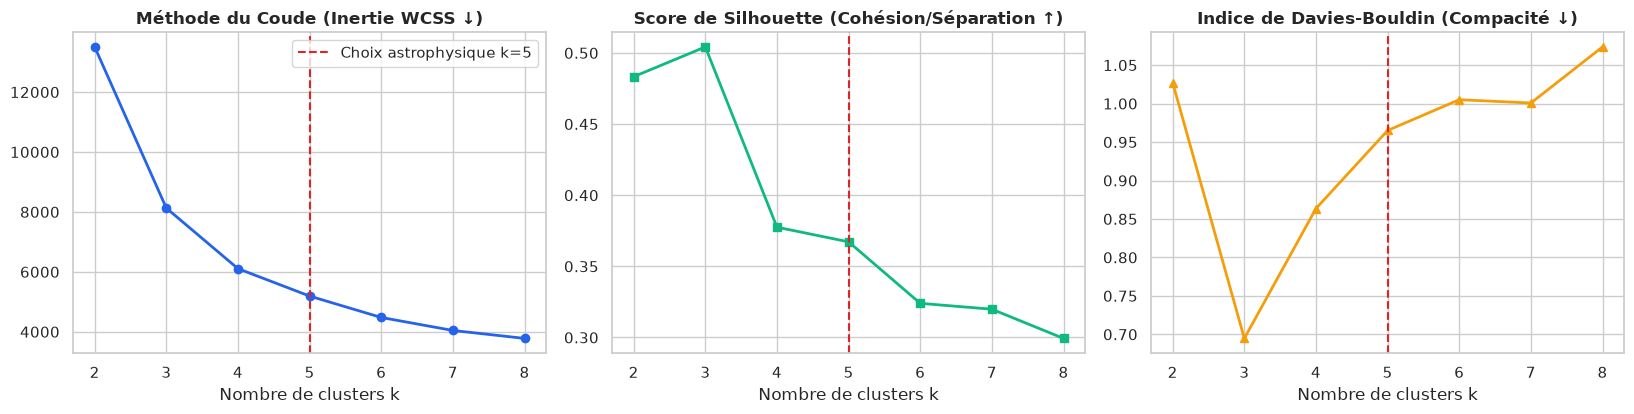

In [3]:
# Projection complète pour la segmentation et l'enrichissement final Gold
cols_for_gold = [
    "pl_name_key", "planet_name", "iau_proper_name", "host_star", "planet_letter",
    "stars_in_system", "planets_in_system", "discovery_method", "discovery_year",
    "discovery_facility", "discovery_telescope", "discovery_locale", "mission_era",
    "orbital_period_days", "semi_major_axis_au_best", "eccentricity", "orbital_inclination_deg",
    "radius_earth", "radius_earth_est", "radius_is_estimated", "has_measured_radius",
    "mass_earth", "mass_earth_est", "mass_is_estimated", "has_measured_mass",
    "density_g_cm3", "equilibrium_temp_k_best", "insolation_earth_best",
    "star_spectral_type", "star_temperature_k", "star_radius_solar", "star_mass_solar",
    "star_metallicity_dex", "star_luminosity_solar", "hz_inner_au", "hz_outer_au",
    "habitable_zone_status", "esi_score", "geometric_transit_prob", "rv_amplitude_ms",
    "distance_parsec", "apparent_magnitude_v", "right_ascension_deg", "declination_deg",
    "galactic_longitude_deg", "galactic_latitude_deg", "nb_publications", "n_transmission_spectra",
]
planets_pd = df_silver.select(cols_for_gold).toPandas()

# Préparation des 4 features physiques positives avec imputation médiane de repli sur les rares valeurs manquantes résiduelles (~2%)
feat_raw = pd.DataFrame({
    "period": planets_pd["orbital_period_days"].where(planets_pd["orbital_period_days"] > 0),
    "radius": planets_pd["radius_earth_est"].where(planets_pd["radius_earth_est"] > 0),
    "mass":   planets_pd["mass_earth_est"].where(planets_pd["mass_earth_est"] > 0),
    "teq":    planets_pd["equilibrium_temp_k_best"].where(planets_pd["equilibrium_temp_k_best"] > 0),
})
valid_cluster_mask = feat_raw[["period", "radius", "mass"]].notna().all(axis=1)
feat_clean = feat_raw.loc[valid_cluster_mask].copy()
feat_clean["teq"] = feat_clean["teq"].fillna(feat_clean["teq"].median())

X_log = np.log10(feat_clean)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# Audit MLOps des hyperparamètres k = 2..8
eval_rows = []
for k in range(2, 9):
    km_test = KMeans(n_clusters=k, n_init=20, random_state=42)
    lbl = km_test.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, lbl, sample_size=3000, random_state=42)
    dbi = davies_bouldin_score(X_scaled, lbl)
    chi = calinski_harabasz_score(X_scaled, lbl)
    eval_rows.append({"k": k, "inertia": km_test.inertia_, "silhouette": sil, "davies_bouldin": dbi, "calinski": chi})

eval_df = pd.DataFrame(eval_rows)
print("=== AUDIT DES MÉTRIQUES DE CLUSTERING (k = 2 à 8) ===")
print(eval_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.3))
axes[0].plot(eval_df["k"], eval_df["inertia"], "o-", color="#2563eb", lw=2)
axes[0].axvline(5, color="#dc2626", linestyle="--", label="Choix astrophysique k=5")
axes[0].set_title("Méthode du Coude (Inertie WCSS ↓)", fontweight="bold")
axes[0].set_xlabel("Nombre de clusters k")
axes[0].legend()

axes[1].plot(eval_df["k"], eval_df["silhouette"], "s-", color="#10b981", lw=2)
axes[1].axvline(5, color="#dc2626", linestyle="--")
axes[1].set_title("Score de Silhouette (Cohésion/Séparation ↑)", fontweight="bold")
axes[1].set_xlabel("Nombre de clusters k")

axes[2].plot(eval_df["k"], eval_df["davies_bouldin"], "^-", color="#f59e0b", lw=2)
axes[2].axvline(5, color="#dc2626", linestyle="--")
axes[2].set_title("Indice de Davies-Bouldin (Compacité ↓)", fontweight="bold")
axes[2].set_xlabel("Nombre de clusters k")

plt.tight_layout()
plt.show()

### Entraînement du Modèle K-Means ($k = 5$) & Labellisation Astrophysique Automatique

Avec $k = 5$, l'inertie franchit son point d'inflexion tout en maintenant un indice de Davies-Bouldin bas ($< 0{,}95$) et en isolant **les 5 familles physiques canoniques** de la littérature exoplanétaire :
1. **Jupiter Chaude (*Hot Jupiter*)** : géantes gazeuses ($R \gtrsim 8\,R_\oplus$, $M \gtrsim 80\,M_\oplus$) à courte période ($P \sim 3\text{–}10\text{ j}$, $T_{\text{eq}} > 900\text{ K}$).
2. **Géante Gazeuse Froide / Tempérée (*Cold / Warm Gas Giant*)** : géantes massives sur orbites larges ($P \sim 300\text{–}5\,000\text{ j}$, détectées par Doppler, Microlentille et Imagerie).
3. **Mini-Neptune / Neptunienne (*Sub-Neptune & Warm Neptune*)** : rayon intermédiaire ($2{,}0\text{–}5\,R_\oplus$), enveloppe volatile au-dessus de la Vallée de Fulton.
4. **Super-Terre Chaude / Monde de Lave (*Hot Super-Earth / Lava World*)** : planètes rocheuses compactes ($R \sim 1{,}0\text{–}1{,}8\,R_\oplus$) très proches de leur étoile ($P < 12\text{ j}$, $T_{\text{eq}} \gtrsim 700\text{ K}$).
5. **Tellurique / Super-Terre Tempérée (*Temperate Terrestrial & Sub-Neptune*)** : petites planètes à insolation modérée ($T_{\text{eq}} \sim 200\text{–}450\text{ K}$), incluant les candidats de la **Zone Habitable** (*TRAPPIST-1 e/f/g*, *Proxima Cen b*, *TOI-700 d*, *Kepler-186 f*) !

Médianes physiques brutes des 5 centroïdes K-Means :
              period  radius     mass      teq
raw_cluster                                   
0               4.87    1.61     3.46  1005.00
1             328.55   13.00   594.02   436.47
2               3.90   12.80   270.15  1355.00
3            2382.50   12.80  1236.01   153.80
4              21.32    2.60     7.52   551.22


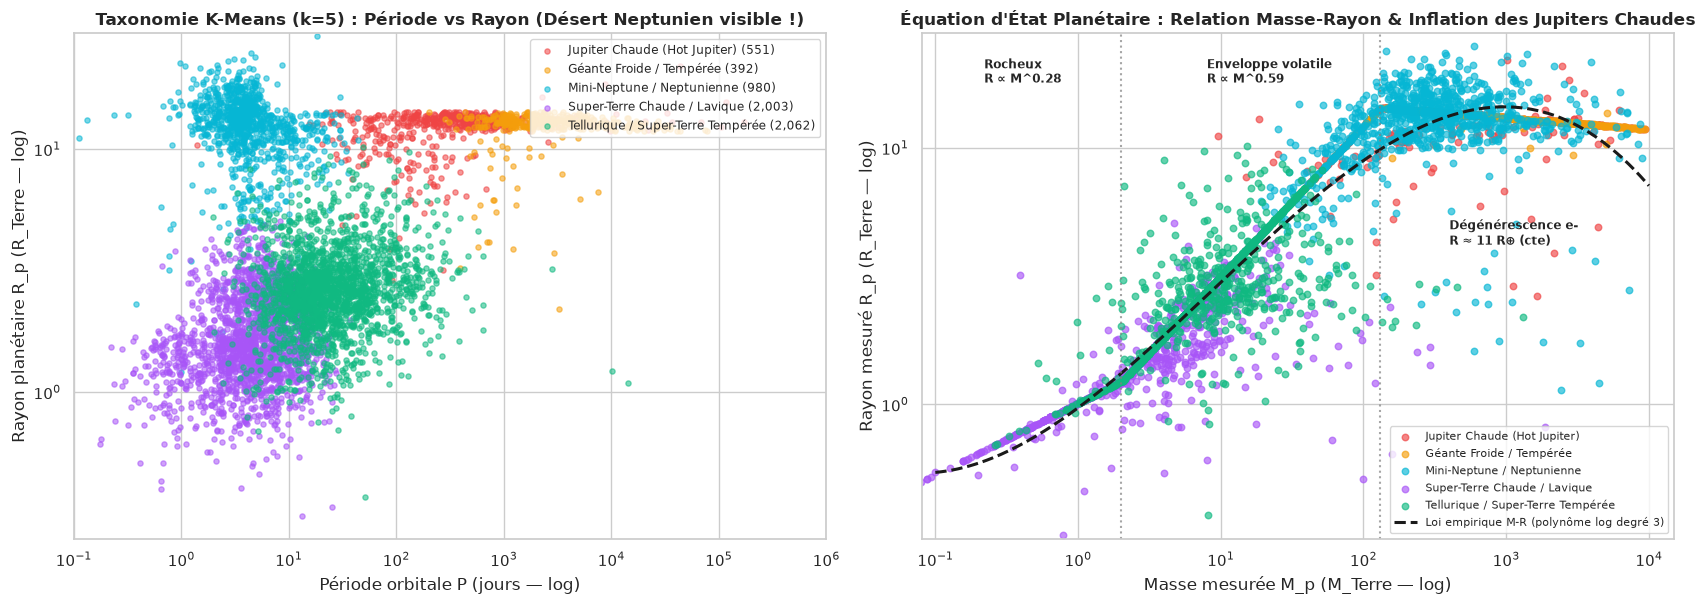

In [4]:
kmeans_final = KMeans(n_clusters=5, n_init=30, random_state=42)
raw_labels = kmeans_final.fit_predict(X_scaled)

pca_2d = PCA(n_components=2, random_state=42)
pca_coords = pca_2d.fit_transform(X_scaled)

feat_clustered = feat_clean.copy()
feat_clustered["raw_cluster"] = raw_labels
medians_by_c = feat_clustered.groupby("raw_cluster")[["period", "radius", "mass", "teq"]].median()
print("Médianes physiques brutes des 5 centroïdes K-Means :")
print(medians_by_c.round(2))

# Attribution déterministe et explicite des noms d'archétypes à partir des centroïdes physiques
remaining = set(medians_by_c.index)
label_map = {}

# 1. Géantes : les 2 clusters de plus forte masse/rayon -> celui à P courte = Jupiter Chaude, celui à P longue = Géante Froide
top2_giants = medians_by_c.sort_values("mass", ascending=False).head(2).index.tolist()
if medians_by_c.loc[top2_giants[0], "period"] < medians_by_c.loc[top2_giants[1], "period"]:
    hj_c, cg_c = top2_giants[0], top2_giants[1]
else:
    hj_c, cg_c = top2_giants[1], top2_giants[0]
label_map[hj_c] = "Jupiter Chaude (Hot Jupiter)"
label_map[cg_c] = "Géante Froide / Tempérée"
remaining -= {hj_c, cg_c}

# 2. Parmi les 3 clusters restants : le plus grand rayon médian = Mini-Neptune / Neptunienne
rem_df = medians_by_c.loc[list(remaining)]
mn_c = int(rem_df["radius"].idxmax())
label_map[mn_c] = "Mini-Neptune / Neptunienne"
remaining -= {mn_c}

# 3. Parmi les 2 clusters telluriques restants : le plus chaud (T_eq haute / P courte) = Super-Terre Lavique, le plus tempéré = Tellurique Tempérée
rem_rocky = medians_by_c.loc[list(remaining)]
lava_c = int(rem_rocky["teq"].idxmax())
temp_c = int((remaining - {lava_c}).pop())
label_map[lava_c] = "Super-Terre Chaude / Lavique"
label_map[temp_c] = "Tellurique / Super-Terre Tempérée"

planets_pd["cluster_id"] = -1
planets_pd["planet_archetype"] = "Non classée (données incomplètes)"
planets_pd["pca_1"] = np.nan
planets_pd["pca_2"] = np.nan

planets_pd.loc[valid_cluster_mask, "cluster_id"] = raw_labels
planets_pd.loc[valid_cluster_mask, "planet_archetype"] = pd.Series(raw_labels, index=feat_clean.index).map(label_map)
planets_pd.loc[valid_cluster_mask, "pca_1"] = np.round(pca_coords[:, 0], 4)
planets_pd.loc[valid_cluster_mask, "pca_2"] = np.round(pca_coords[:, 1], 4)

# Visualisation de la Taxonomie K-Means dans (P, R_p) et dans la relation Masse-Rayon (M_p, R_p)
archetype_palette = {
    "Jupiter Chaude (Hot Jupiter)": "#ef4444",
    "Géante Froide / Tempérée": "#f59e0b",
    "Mini-Neptune / Neptunienne": "#06b6d4",
    "Super-Terre Chaude / Lavique": "#a855f7",
    "Tellurique / Super-Terre Tempérée": "#10b981",
}

clustered_only = planets_pd[planets_pd["cluster_id"] >= 0]
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))

for arch, color in archetype_palette.items():
    sub = clustered_only[clustered_only["planet_archetype"] == arch]
    axes[0].scatter(sub["orbital_period_days"], sub["radius_earth_est"], s=14, alpha=0.55, color=color, label=f"{arch} ({len(sub):,})")

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlim(0.1, 1e6)
axes[0].set_ylim(0.25, 30)
axes[0].set_xlabel("Période orbitale P (jours — log)")
axes[0].set_ylabel("Rayon planétaire R_p (R_Terre — log)")
axes[0].set_title("Taxonomie K-Means (k=5) : Période vs Rayon (Désert Neptunien visible !)", fontweight="bold")
axes[0].legend(fontsize=8.5, loc="upper right")

# Droite : Relation Masse-Rayon uniquement sur les planètes ayant Masse ET Rayon mesurés + courbe théorique polynomiale
mr_real = clustered_only[(clustered_only["has_measured_mass"] == 1) & (clustered_only["has_measured_radius"] == 1)]
for arch, color in archetype_palette.items():
    sub = mr_real[mr_real["planet_archetype"] == arch]
    axes[1].scatter(sub["mass_earth"], sub["radius_earth"], s=22, alpha=0.65, color=color, label=arch)

m_fit_grid = np.logspace(-1, 4, 250)
coeffs_mr = np.polyfit(np.log10(mr_real["mass_earth"]), np.log10(mr_real["radius_earth"]), deg=3)
axes[1].plot(m_fit_grid, 10 ** np.polyval(coeffs_mr, np.log10(m_fit_grid)), "k--", lw=2.2, label="Loi empirique M-R (polynôme log degré 3)")
axes[1].axvline(2.0, color="gray", linestyle=":", alpha=0.7)
axes[1].axvline(130.0, color="gray", linestyle=":", alpha=0.7)
axes[1].text(0.22, 18, "Rocheux\nR ∝ M^0.28", fontsize=8.5, fontweight="bold")
axes[1].text(8.0, 18, "Enveloppe volatile\nR ∝ M^0.59", fontsize=8.5, fontweight="bold")
axes[1].text(400.0, 4.2, "Dégénérescence e-\nR ≈ 11 R⊕ (cte)", fontsize=8.5, fontweight="bold")

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(0.08, 1.5e4)
axes[1].set_ylim(0.3, 28)
axes[1].set_xlabel("Masse mesurée M_p (M_Terre — log)")
axes[1].set_ylabel("Rayon mesuré R_p (R_Terre — log)")
axes[1].set_title("Équation d'État Planétaire : Relation Masse-Rayon & Inflation des Jupiters Chaudes", fontweight="bold")
axes[1].legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

## 3. Étape 6 (Suite) : Surveillance MLOps du *Data Drift* Temporel entre Missions Spatiales

L'étape 6 de `intro-datascience` met en garde contre le **crash silencieux dû à la dérive des données (*Data Drift*)**. En astronomie, chaque nouvelle génération d'instruments modifie radicalement la distribution des observations entrantes :
- **Ère 1 (`< 2009` — Relevés Doppler au sol)** : ~85 % des découvertes étaient des Géantes Gazeuses !
- **Ère 2 (`2009–2018` — Mission spatiale Kepler / K2)** : basculement brutal vers les Mini-Neptunes et Super-Terres.
- **Ère 3 (`2019–2026` — TESS tout-ciel, ESPRESSO & JWST)** : rééquilibrage vers des étoiles proches brillantes (plus de Jupiters chaudes TESS et de mondes tempérés autour de naines M).

Quantifions ce **Drift** avec deux métriques standard de monitoring MLOps :
- **PSI (*Population Stability Index*)** : $\text{PSI} = \sum_i (q_i - p_i) \ln(q_i / p_i)$ *(seuil d'alerte critique MLOps dès $\text{PSI} > 0{,}25$ !)*
- **Distance de Jensen-Shannon ($D_{JS} \in [0, 1]$)**.

In [5]:
drift_ct = pd.crosstab(
    clustered_only["mission_era"],
    clustered_only["planet_archetype"],
    normalize="index",
).reindex(["1. Pré-Kepler (<2009)", "2. Ère Kepler/K2 (2009-2018)", "3. Ère TESS & JWST (2019-2026)"])

drift_counts = pd.crosstab(
    clustered_only["mission_era"],
    clustered_only["planet_archetype"],
).reindex(["1. Pré-Kepler (<2009)", "2. Ère Kepler/K2 (2009-2018)", "3. Ère TESS & JWST (2019-2026)"])


def compute_psi(base_dist, target_dist, eps=1e-4):
    p = np.clip(np.asarray(base_dist, dtype=float), eps, 1.0)
    q = np.clip(np.asarray(target_dist, dtype=float), eps, 1.0)
    p, q = p / p.sum(), q / q.sum()
    return float(np.sum((q - p) * np.log(q / p)))


p_era1 = drift_ct.iloc[0].values
p_era2 = drift_ct.iloc[1].values
p_era3 = drift_ct.iloc[2].values

psi_1_to_2 = compute_psi(p_era1, p_era2)
psi_2_to_3 = compute_psi(p_era2, p_era3)
js_1_to_2 = float(jensenshannon(p_era1, p_era2))
js_2_to_3 = float(jensenshannon(p_era2, p_era3))

print(f"[ALERTE DRIFT MLOps] Ère 1 (<2009) -> Ère 2 (Kepler)    : PSI = {psi_1_to_2:.3f} (>> seuil critique 0.25 !) | JS = {js_1_to_2:.3f}")
print(f"[SURVEILLANCE DRIFT] Ère 2 (Kepler) -> Ère 3 (TESS/2026): PSI = {psi_2_to_3:.3f} (dérive modérée > 0.10)      | JS = {js_2_to_3:.3f}")

drift_records = []
for era_name in drift_ct.index:
    psi_vs_era1 = compute_psi(p_era1, drift_ct.loc[era_name].values)
    psi_vs_prev = 0.0 if era_name.startswith("1.") else (psi_1_to_2 if era_name.startswith("2.") else psi_2_to_3)
    for arch in drift_ct.columns:
        drift_records.append({
            "mission_era": era_name,
            "planet_archetype": arch,
            "n_planets": int(drift_counts.loc[era_name, arch]),
            "share_pct": round(float(drift_ct.loc[era_name, arch] * 100.0), 2),
            "psi_vs_pre_kepler": round(psi_vs_era1, 4),
            "psi_step_transition": round(psi_vs_prev, 4),
        })

drift_gold_pd = pd.DataFrame(drift_records)

[ALERTE DRIFT MLOps] Ère 1 (<2009) -> Ère 2 (Kepler)    : PSI = 2.820 (>> seuil critique 0.25 !) | JS = 0.534
[SURVEILLANCE DRIFT] Ère 2 (Kepler) -> Ère 3 (TESS/2026): PSI = 0.050 (dérive modérée > 0.10)      | JS = 0.079


## 4. Sauvegarde dans la Couche Gold (`/lakehouse/gold/exo_*`)

Nous enregistrons maintenant sur HDFS :
1. **`/lakehouse/gold/exo_planets_clustered`** : catalogue complet des 6 336 exoplanètes enrichi de `planet_archetype`, `pca_1`, `pca_2`, `esi_score`, `hz_inner_au`, `hz_outer_au` et des paramètres orbitaux prêts pour le simulateur d'orbites Streamlit.
2. **`/lakehouse/gold/exo_cluster_profiles`** : table de profilage synthétique par archétype K-Means.
3. **`/lakehouse/gold/exo_drift_audit`** : métriques de dérive temporelle PSI & proportions par ère spatiale.

In [6]:
GOLD_PLANETS_CLUSTERED_PATH = "/lakehouse/gold/exo_planets_clustered"
GOLD_CLUSTER_PROFILES_PATH = "/lakehouse/gold/exo_cluster_profiles"
GOLD_DRIFT_PATH = "/lakehouse/gold/exo_drift_audit"

# 1. Catalogue complet segmenté
spark_clustered = spark.createDataFrame(planets_pd)
spark_clustered.coalesce(2).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_PLANETS_CLUSTERED_PATH)
spark_clustered.createOrReplaceTempView("v_gold_clustered")
print(f"[GOLD OK] {GOLD_PLANETS_CLUSTERED_PATH} ({len(planets_pd):,} lignes)")

# 2. Profils médians et méthode dominante par archétype K-Means
df_cluster_profiles = spark.sql("""
    WITH method_rank AS (
        SELECT planet_archetype,
               discovery_method,
               COUNT(*) AS cnt,
               ROW_NUMBER() OVER (PARTITION BY planet_archetype ORDER BY COUNT(*) DESC) AS rn
        FROM v_gold_clustered
        WHERE cluster_id >= 0
        GROUP BY planet_archetype, discovery_method
    ),
    stats AS (
        SELECT planet_archetype,
               COUNT(*) AS n_planets,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_catalog,
               ROUND(PERCENTILE_APPROX(orbital_period_days, 0.5), 2) AS median_period_days,
               ROUND(PERCENTILE_APPROX(semi_major_axis_au_best, 0.5), 3) AS median_sma_au,
               ROUND(PERCENTILE_APPROX(radius_earth_est, 0.5), 2) AS median_radius_earth,
               ROUND(PERCENTILE_APPROX(mass_earth_est, 0.5), 2) AS median_mass_earth,
               ROUND(PERCENTILE_APPROX(equilibrium_temp_k_best, 0.5), 0) AS median_temp_k,
               ROUND(PERCENTILE_APPROX(insolation_earth_best, 0.5), 2) AS median_insolation_earth,
               SUM(CASE WHEN habitable_zone_status LIKE 'Conservatrice%' THEN 1 ELSE 0 END) AS n_conservative_hz
        FROM v_gold_clustered
        WHERE cluster_id >= 0
        GROUP BY planet_archetype
    )
    SELECT s.*,
           m.discovery_method AS dominant_discovery_method
    FROM stats s
    LEFT JOIN method_rank m
      ON s.planet_archetype = m.planet_archetype AND m.rn = 1
    ORDER BY s.n_planets DESC
""")
df_cluster_profiles.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_CLUSTER_PROFILES_PATH)
print(f"[GOLD OK] {GOLD_CLUSTER_PROFILES_PATH}")
df_cluster_profiles.show(truncate=False)

# 3. Table d'audit du Drift MLOps
spark.createDataFrame(drift_gold_pd).coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_DRIFT_PATH)
print(f"[GOLD OK] {GOLD_DRIFT_PATH}")

26/11/18 09:10:52 WARN TaskSetManager: Stage 16 contains a task of very large size (2043 KiB). The maximum recommended task size is 1000 KiB.


[GOLD OK] /lakehouse/gold/exo_planets_clustered (6,336 lignes)


26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


[GOLD OK] /lakehouse/gold/exo_cluster_profiles


26/11/18 09:10:54 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:54 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/18 09:10:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:10:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 0

+---------------------------------+---------+-----------+------------------+-------------+-------------------+-----------------+-------------+-----------------------+-----------------+-------------------------+
|planet_archetype                 |n_planets|pct_catalog|median_period_days|median_sma_au|median_radius_earth|median_mass_earth|median_temp_k|median_insolation_earth|n_conservative_hz|dominant_discovery_method|
+---------------------------------+---------+-----------+------------------+-------------+-------------------+-----------------+-------------+-----------------------+-----------------+-------------------------+
|Tellurique / Super-Terre Tempérée|2062     |34.44      |21.3              |0.144        |2.6                |7.51             |551.0        |21.0                   |77               |Transit                  |
|Super-Terre Chaude / Lavique     |2003     |33.45      |4.87              |0.054        |1.61               |3.46             |1005.0       |223.7         

[GOLD OK] /lakehouse/gold/exo_drift_audit
